<a href="https://colab.research.google.com/github/thakurakanksha288/AI-ASSIGNMENT-PYTHON-/blob/main/1024160019_assignment7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The Problem: Raw data is often a chaotic "cloud." Businesses cannot create a single strategy that fits everyone.
The AI Solution: Using Unsupervised K-Means Clustering, we partition data into distinct, homogeneous groups. This project doesn't just find groups; it mathematically proves the Optimal Number of Clusters using the Elbow Method and Silhouette Analysis, ensuring the groupings are scientifically sound and not just guessed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Create synthetic Customer Data
np.random.seed(42)
data = np.vstack([
    np.random.normal(20, 5, (100, 2)), # Low Spenders
    np.random.normal(50, 8, (100, 2)), # Average
    np.random.normal(80, 5, (100, 2))  # High Spenders
])
df = pd.DataFrame(data, columns=['Income', 'Spending'])

# Scaling is CRITICAL for K-Means (Distance-based)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

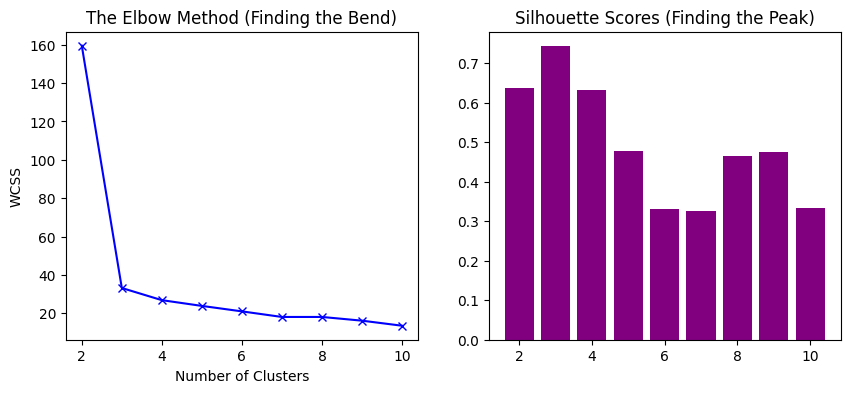

In [2]:
wcss = []
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(df_scaled)
    wcss.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(df_scaled, kmeans.labels_))

# Plotting the Elbow Method
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(K_range, wcss, 'bx-')
plt.title('The Elbow Method (Finding the Bend)')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

# Plotting Silhouette Scores
plt.subplot(1, 2, 2)
plt.bar(K_range, sil_scores, color='purple')
plt.title('Silhouette Scores (Finding the Peak)')
plt.show()

To help a non-technical person understand these graphs:

The Elbow Method: We look for the "arm's elbow." It’s the point where adding more clusters stops providing significant value. It represents the Optimal Trade-off between complexity and accuracy.

Silhouette Score: This measures how similar an object is to its own cluster compared to others. A higher peak means the clusters are well-separated and not overlapping.

In [3]:
import plotly.express as px

# Final Model with Optimal K (e.g., K=3)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42)
df['Cluster'] = kmeans.fit_transform(df_scaled).argmax(axis=1)
df['Cluster'] = df['Cluster'].astype(str)

fig = px.scatter(df, x='Income', y='Spending', color='Cluster',
                 title=f"AI Customer Segmentation: {optimal_k} Optimal Personas Identified",
                 color_discrete_sequence=px.colors.qualitative.Prism)
fig.update_layout(template='plotly_dark')
fig.show()

Ultimately, this project demonstrates the power of data partitioning to drive strategic decision-making. By combining the Elbow Method's efficiency with Silhouette Analysis's precision, we transformed a disorganized dataset into three distinct, mathematically-validated personas. This approach ensures that we aren't just finding patterns—we are uncovering the true structural logic of the data, allowing for targeted interventions that are both data-driven and highly efficient.